# Figure S11 — CAID3 Disorder-PDB scored by IDR length: all six panels in one figure

Panels A–D (`figure_S11A–D.ipynb`: AUC, APS, Fmax and MCC of every CAID3 disorder predictor in four IDR-length bins) in a 2 × 2 grid, with the shared legend to the right of B, and panels E–F (`figure_S11E–F.ipynb`: top 40 by MCC for IDRs of 50–99 and ≥100 residues, asterisk = significantly ahead of metapredict V3) below at full width. Same bins, scoring, bootstrap and drawing as the panel notebooks (see the README); only the legend moves, from beside A to beside B, so it sits in the right margin.

**Output:** `figures/figure_S11.pdf`

In [1]:
import matplotlib.pyplot as plt

from caid3_panels import load_predictions, load_reference, rank_predictors
from figtools import apply_style, label_panels, require_metapredict_3_1, save_panel
from idr_length import (IDR_LENGTH_BINS, describe_bins, field_panel, paired_bootstrap,
                        print_metapredict_ranks_by_bin, rank_by_idr_length, ranking_panel,
                        significantly_ahead, stratify_reference)

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

FIELD_METRICS = ['auc', 'aps', 'fmax', 'mcc']  # panels A-D, in reading order of the 2 x 2 grid
LEGEND_METRIC = 'aps'  # the legend goes beside B (top right) instead of beside A
RANKING_BINS = [IDR_LENGTH_BINS[2], IDR_LENGTH_BINS[3]]  # panels E-F: IDRs of 50-99 and >=100 residues
TOP_N = 40
PANEL_LETTERS = 'ABCDEF'
# figure width matches the full-width E-F panels; each row is as tall as one single panel (inches)
FIGURE_WIDTH_IN = 6.5
ROW_HEIGHT_IN = 2.2

metapredict 3.1.0+7.g7dcf52c.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
# A-D: all predictors scored within each IDR-length bin (~1 min)
reference = load_reference()
predictions = load_predictions()
describe_bins(reference)
rankings = rank_by_idr_length(reference, predictions)
print_metapredict_ranks_by_bin(rankings)

every bin keeps all 67838 ordered residues
IDRs    <20 aa:  158 IDRs,   2123 disordered residues
IDRs  20–49 aa:  135 IDRs,   4042 disordered residues
IDRs  50–99 aa:   68 IDRs,   4801 disordered residues
IDRs   ≥100 aa:   94 IDRs,  20435 disordered residues


IDRs <20 aa (66 predictors)
  AUC   V1 0.825 (rank 40), V2 0.840 (rank 31), V3 0.798 (rank 49)
  APS   V1 0.233 (rank 25), V2 0.181 (rank 40), V3 0.151 (rank 51)
  Fmax  V1 0.328 (rank 25), V2 0.304 (rank 32), V3 0.265 (rank 47)
  MCC   V1 0.306 (rank 25), V2 0.283 (rank 33), V3 0.243 (rank 47)
IDRs 20–49 aa (66 predictors)
  AUC   V1 0.835 (rank 51), V2 0.871 (rank 34), V3 0.873 (rank 33)
  APS   V1 0.404 (rank 33), V2 0.386 (rank 41), V3 0.401 (rank 35)
  Fmax  V1 0.423 (rank 49), V2 0.458 (rank 34), V3 0.460 (rank 32)
  MCC   V1 0.391 (rank 47), V2 0.425 (rank 35), V3 0.430 (rank 30)
IDRs 50–99 aa (66 predictors)
  AUC   V1 0.872 (rank 50), V2 0.895 (rank 39), V3 0.928 (rank 13)
  APS   V1 0.573 (rank 39), V2 0.638 (rank 20), V3 0.743 (rank 6)
  Fmax  V1 0.560 (rank 43), V2 0.658 (rank 11), V3 0.727 (rank 5)
  MCC   V1 0.529 (rank 44), V2 0.637 (rank 12), V3 0.710 (rank 5)
IDRs ≥100 aa (66 predictors)
  AUC   V1 0.907 (rank 43), V2 0.937 (rank 25), V3 0.954 (rank 7)
  APS   V1 0.825

In [3]:
# E-F: rankings within the two longest bins and the paired bootstrap against V3 (~10-30 s each)
ranking_by_bin = {}
significant_mcc_by_bin = {}
for shortest, longest, label in RANKING_BINS:
    binned = stratify_reference(reference, shortest, longest)
    ranking_by_bin[label] = rank_predictors(binned, predictions, dataset=f'IDRs {label} aa')
    intervals = paired_bootstrap(binned, predictions, ranking_by_bin[label])
    significant_mcc_by_bin[label] = significantly_ahead(intervals['mcc'])
    print(f'IDRs {label} aa: significantly ahead of V3 on MCC: {significant_mcc_by_bin[label]}')

IDRs 50–99 aa: significantly ahead of V3 on MCC: []


IDRs ≥100 aa: significantly ahead of V3 on MCC: ['PUNCH2']


Wrote figures/figure_S11.pdf


PosixPath('figures/figure_S11.pdf')

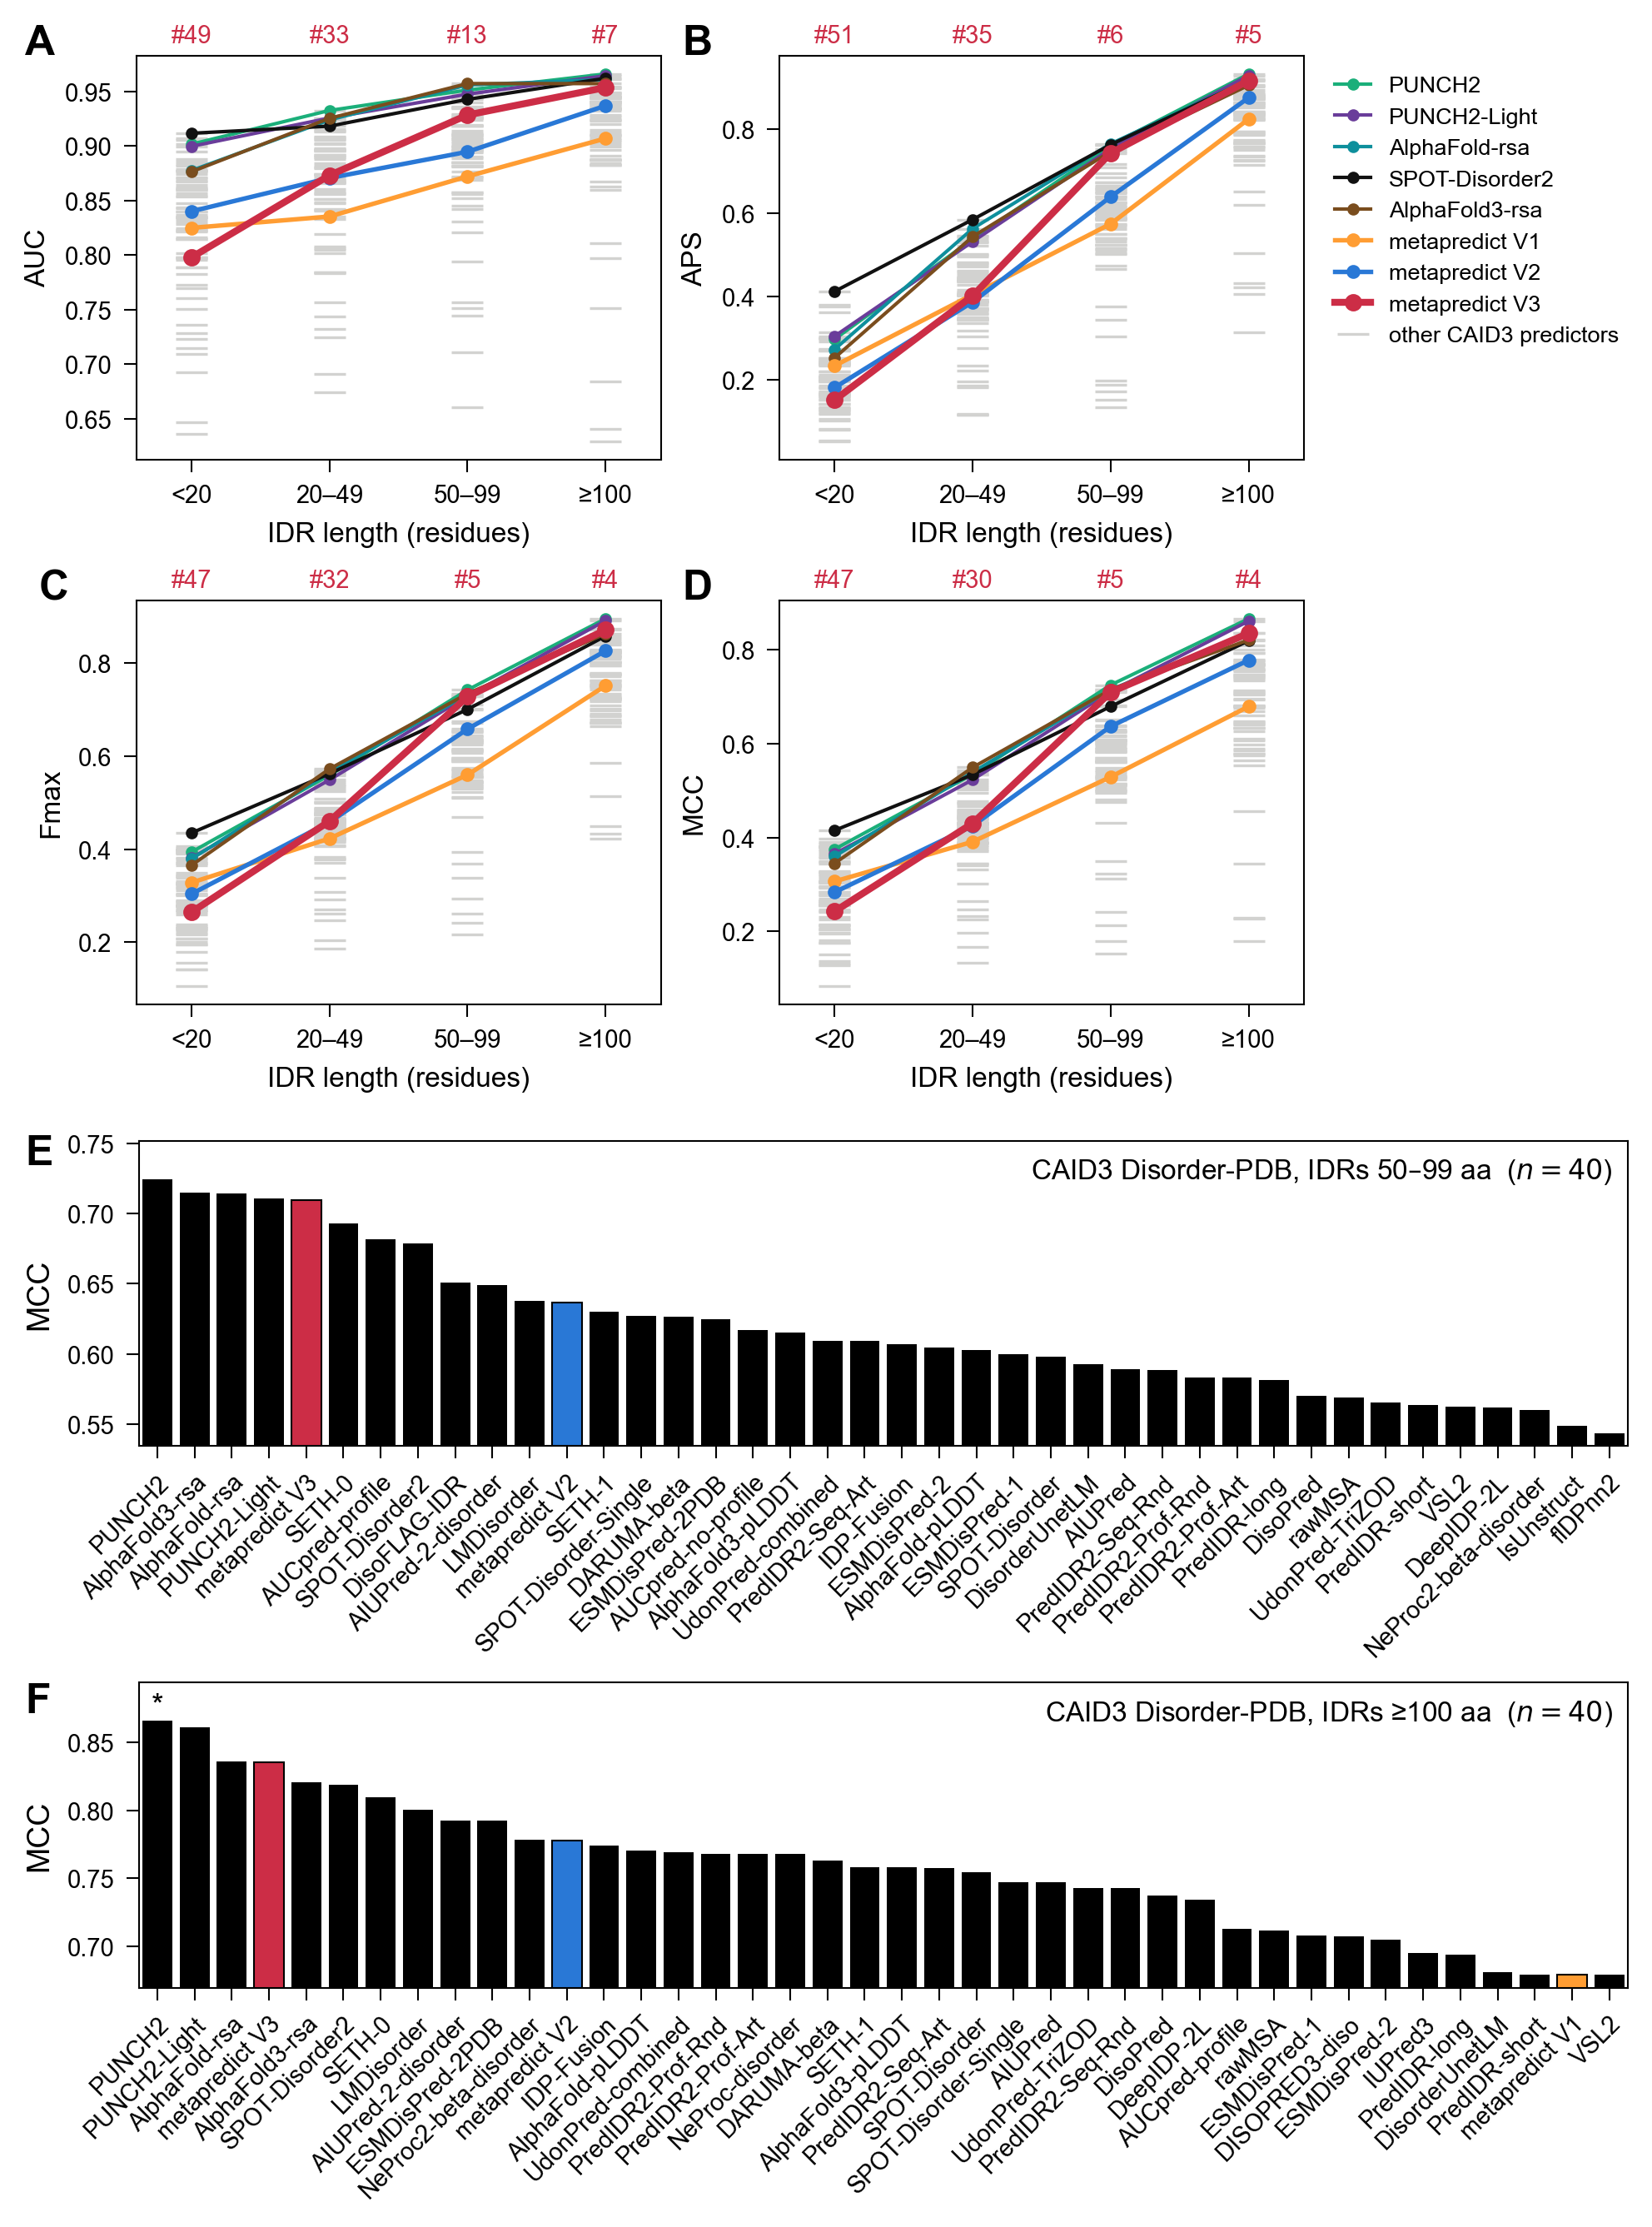

In [4]:
fig = plt.figure(figsize=(FIGURE_WIDTH_IN, ROW_HEIGHT_IN * 4), dpi=150, layout='constrained')
top, bottom = fig.subfigures(2, 1)

field_axes = top.subplots(2, 2).flatten()
for ax, attr in zip(field_axes, FIELD_METRICS):
    field_panel(ax, rankings, attr, show_legend=(attr == LEGEND_METRIC))

ranking_axes = bottom.subplots(len(RANKING_BINS), 1)
for ax, (_shortest, _longest, label) in zip(ranking_axes, RANKING_BINS):
    ranking_panel(ax, ranking_by_bin[label], 'mcc', f'CAID3 Disorder-PDB, IDRs {label} aa',
                  significant_mcc_by_bin[label], top_n=TOP_N)

label_panels(fig, [*field_axes, *ranking_axes], PANEL_LETTERS)
save_panel(fig, 'figure_S11')